# Chimera searching

In [1]:
from Bio import SeqIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%cd /groups/cress/projects/efactors/jack/insertion_mapping/data/community_editing/DKDTH4_251001

/groups/cress/projects/efactors/jack/insertion_mapping/data/community_editing/DKDTH4_251001


## General Functions
Namely, chimera parse

In [2]:
def parse_uchimealn(filepath):
    queries = []
    models = []
    with open(filepath, "r") as file:
        lines = file.readlines()
        qidx = 0
        for line in lines:
            if line.startswith("Query"):
                qidx += 1
                queries.append(line.split(" ")[-1].split("\n")[0])
                models.append("")
            elif line.startswith("Model"):
                models[qidx-1] += line.split("Model   ")[-1].split("\n")[0]

    model_split_starts = [model.index("x") if "x" in model else np.nan for model in models]
    model_b_starts = [model.index("B") for model in models]
    approx_split_sites = [(model.index("B") + model.index("x")) / 2 if "x" in model else model.index("B") for model in models]

    chimera_df = pd.DataFrame({
        "query": queries,
        "model": models,
        "approx_split_site": approx_split_sites,
        "model_split_start": model_split_starts,
        "model_b_start": model_b_starts
    })
    return chimera_df


def read_uchimeout(filepath):
    df = pd.read_csv(filepath, sep="\t", header=None)
    uchimeout_columns = [
        "score",     # 1. Chimera score
        "Q",         # 2. Query sequence label
        "A",         # 3. Parent A sequence label
        "B",         # 4. Parent B sequence label
        "T",         # 5. Top parent sequence label
        "idQM",      # 6. % similarity between query and model
        "idQA",      # 7. % similarity between query and parent A
        "idQB",      # 8. % similarity between query and parent B
        "idAB",      # 9. % similarity between parent A and B
        "idQT",      # 10. % similarity between query and top parent
        "LY",        # 11. Yes votes (left side)
        "LN",        # 12. No votes (left side)
        "LA",        # 13. Abstain votes (left side)
        "RY",        # 14. Yes votes (right side)
        "RN",        # 15. No votes (right side)
        "RA",        # 16. Abstain votes (right side)
        "div",       # 17. Divergence (idQM - idQT)
        "YN"         # 18. Chimera status: Y, N, or ?
    ]
    df.columns = uchimeout_columns
    return df

## Experiments

In [3]:
"""
for i in $(seq -f "%.2f" 0.28 0.1 0.58); do 
# Single representative SILVA
vsearch \
    --uchime_ref LE_containing_amplicons.fasta \
    --db /groups/cress/projects/efactors/jack/insertion_mapping/sequences/SILVA_138_SSURef_NR99_tax_silva_trunc_subset5_level_-2_keep_1.fasta \
    --threads 0 \
    --nonchimeras qc/uchime/nonchimeras.subset_keep_1.minh=$i.fasta \
    --chimeras qc/uchime/chimeras.subset_keep_1.minh=$i.fasta \
    --borderline qc/uchime/borderline.subset_keep_1.minh=$i.fasta \
    --uchimeout qc/uchime/uchimeout.subset_keep_1.minh=$i.txt \
    --uchimealns qc/uchime/uchimeout.subset_keep_1.minh=$i.aln \
    --minh $i
# All hits SILVA subset
vsearch \
    --uchime_ref LE_containing_amplicons.fasta \
    --db /groups/cress/projects/efactors/jack/insertion_mapping/sequences/SILVA_138_SSURef_NR99_tax_silva_trunc_subset5_level_-2.fasta \
    --threads 0 \
    --nonchimeras qc/uchime/nonchimeras.subset.minh=$i.fasta \
    --chimeras qc/uchime/chimeras.subset.minh=$i.fasta \
    --borderline qc/uchime/borderline.subset.minh=$i.fasta \
    --uchimeout qc/uchime/uchimeout.subset.minh=$i.txt \
    --uchimealns qc/uchime/uchimeout.subset.minh=$i.aln \
    --minh $i
# Full SILVA database
vsearch \
    --uchime_ref LE_containing_amplicons.fasta \
    --db /shared/db/silva/latest/fasta/SILVA_138_SSURef_NR99_tax_silva_trunc.replace-whitespace.fasta \
    --threads 0 \
    --nonchimeras qc/uchime/nonchimeras.full.minh=$i.fasta \
    --chimeras qc/uchime/chimeras.full.minh=$i.fasta \
    --borderline qc/uchime/borderline.full.minh=$i.fasta \
    --uchimeout qc/uchime/uchimeout.full.minh=$i.txt \
    --uchimealns qc/uchime/uchimeout.full.minh=$i.aln \
    --minh $i
done

"""

'\nfor i in $(seq -f "%.2f" 0.28 0.1 0.58); do \n# Single representative SILVA\nvsearch     --uchime_ref LE_containing_amplicons.fasta     --db /groups/cress/projects/efactors/jack/insertion_mapping/sequences/SILVA_138_SSURef_NR99_tax_silva_trunc_subset5_level_-2_keep_1.fasta     --threads 0     --nonchimeras qc/uchime/nonchimeras.subset_keep_1.minh=$i.fasta     --chimeras qc/uchime/chimeras.subset_keep_1.minh=$i.fasta     --borderline qc/uchime/borderline.subset_keep_1.minh=$i.fasta     --uchimeout qc/uchime/uchimeout.subset_keep_1.minh=$i.txt     --uchimealns qc/uchime/uchimeout.subset_keep_1.minh=$i.aln     --minh $i\n# All hits SILVA subset\nvsearch     --uchime_ref LE_containing_amplicons.fasta     --db /groups/cress/projects/efactors/jack/insertion_mapping/sequences/SILVA_138_SSURef_NR99_tax_silva_trunc_subset5_level_-2.fasta     --threads 0     --nonchimeras qc/uchime/nonchimeras.subset.minh=$i.fasta     --chimeras qc/uchime/chimeras.subset.minh=$i.fasta     --borderline qc/uchi

In [4]:
"""
for i in $(seq -f "%.2f" 0.28 0.1 0.58); do 
# Gold db
vsearch \
    --uchime_ref LE_containing_amplicons.fasta \
    --db /groups/cress/projects/efactors/jack/insertion_mapping/sequences/gold.fa \
    --threads 0 \
    --nonchimeras qc/uchime/nonchimeras.gold.minh=$i.fasta \
    --chimeras qc/uchime/chimeras.gold.minh=$i.fasta \
    --borderline qc/uchime/borderline.gold.minh=$i.fasta \
    --uchimeout qc/uchime/uchimeout.gold.minh=$i.txt \
    --uchimealns qc/uchime/uchimeout.gold.minh=$i.aln \
    --minh $i
done
"""

'\nfor i in $(seq -f "%.2f" 0.28 0.1 0.58); do \n# Gold db\nvsearch     --uchime_ref LE_containing_amplicons.fasta     --db /groups/cress/projects/efactors/jack/insertion_mapping/sequences/gold.fa     --threads 0     --nonchimeras qc/uchime/nonchimeras.gold.minh=$i.fasta     --chimeras qc/uchime/chimeras.gold.minh=$i.fasta     --borderline qc/uchime/borderline.gold.minh=$i.fasta     --uchimeout qc/uchime/uchimeout.gold.minh=$i.txt     --uchimealns qc/uchime/uchimeout.gold.minh=$i.aln     --minh $i\ndone\n'

In [5]:
import glob

ucdir = "qc/uchime"
outfiles = glob.glob(f"{ucdir}/*.txt")
aln_files = [i.replace("txt", "aln") for i in outfiles]
minh = [i.split("=")[1].split(".txt")[0] for i in outfiles]
dataset = []
for i in outfiles:
    if "subset" in i:
        if "keep_1" in i:
            dataset.append("Single Representative")
        else:
            dataset.append("All Matches")
    elif "full" in i:
        dataset.append("Full SILVA")
    else:
        dataset.append("Gold")

tsvs = [read_uchimeout(i) for i in outfiles]
alns = [parse_uchimealn(i) for i in aln_files]


In [17]:
for chimeras_i in tsvs:
    # chimeras_i = chimeras_i.loc[chimeras_i["YN"] != "N"]
    chimeras_i["A"] = chimeras_i["A"].str.split(";", expand=True).iloc[:, -2]
    chimeras_i["B"] = chimeras_i["B"].str.split(";", expand=True).iloc[:, -2]
    chimeras_i["Chimera"] = chimeras_i["A"] + "/" + chimeras_i["B"]

tsvs[-1]

IndexError: single positional indexer is out-of-bounds

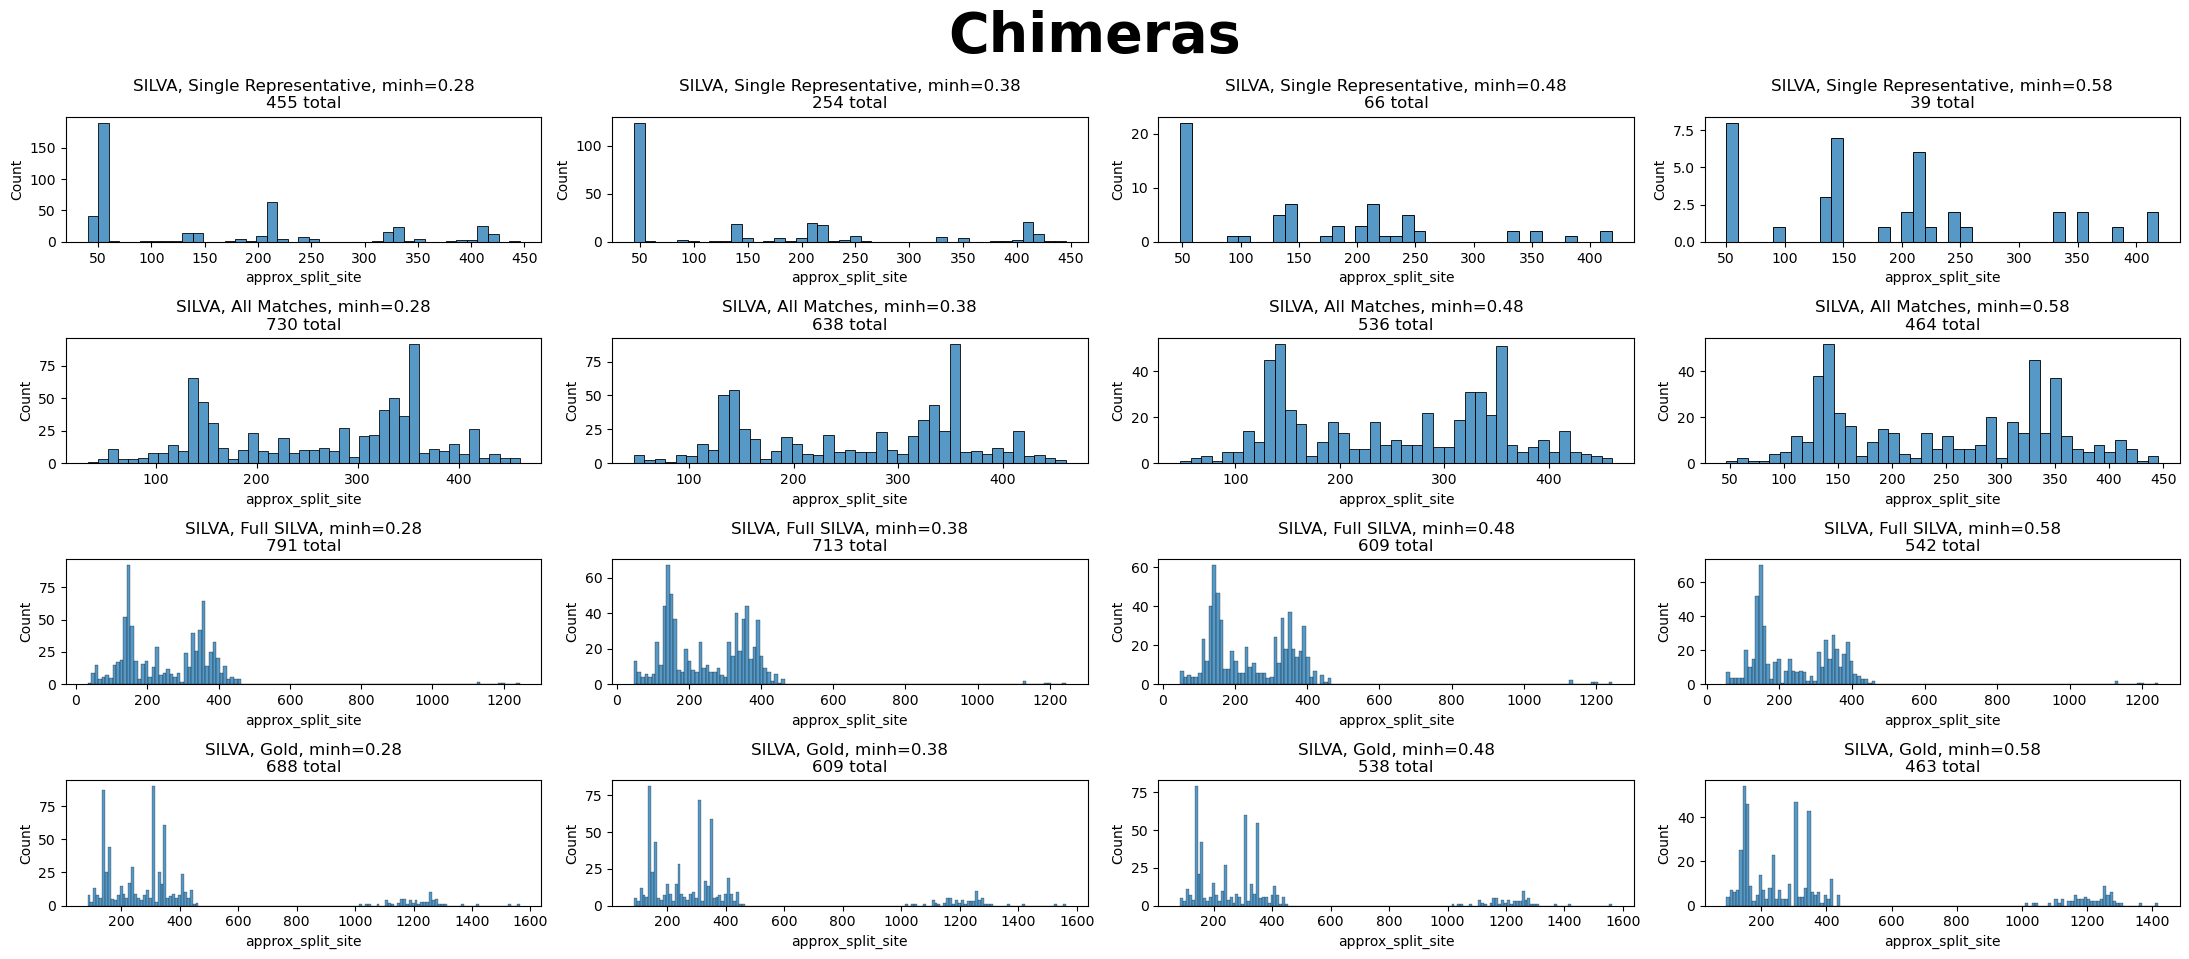

In [6]:
minh_mapper = {'0.28': 0, '0.38': 1, '0.48': 2, '0.58': 3}
ds_mapper = {
    "Single Representative": 0,
    "All Matches": 1,
    "Full SILVA": 2,
    "Gold": 3,
    }

fig, axs = plt.subplots(len(set(dataset)),4,figsize=(22,9))

for idx in range(len(alns)):
    df = tsvs[idx]
    ds_i = dataset[idx]
    minh_i = minh[idx]
    i = ds_mapper[ds_i]
    j = minh_mapper[minh_i]

    chimeras_i = df.loc[df["YN"] != "N"]
    alns_i = alns[idx]

    sns.histplot(alns_i, x="approx_split_site", binwidth=10, ax=axs[i,j])
    axs[i,j].set_title(f"SILVA, {ds_i}, minh={minh_i}\n{alns_i.shape[0]} total")
fig.tight_layout()
fig.suptitle("Chimeras", fontsize=40, fontweight="bold", y=1.06)
plt.show()
# chimeras_i["RY"] - chimeras_i["LY"]
# chimeras_i

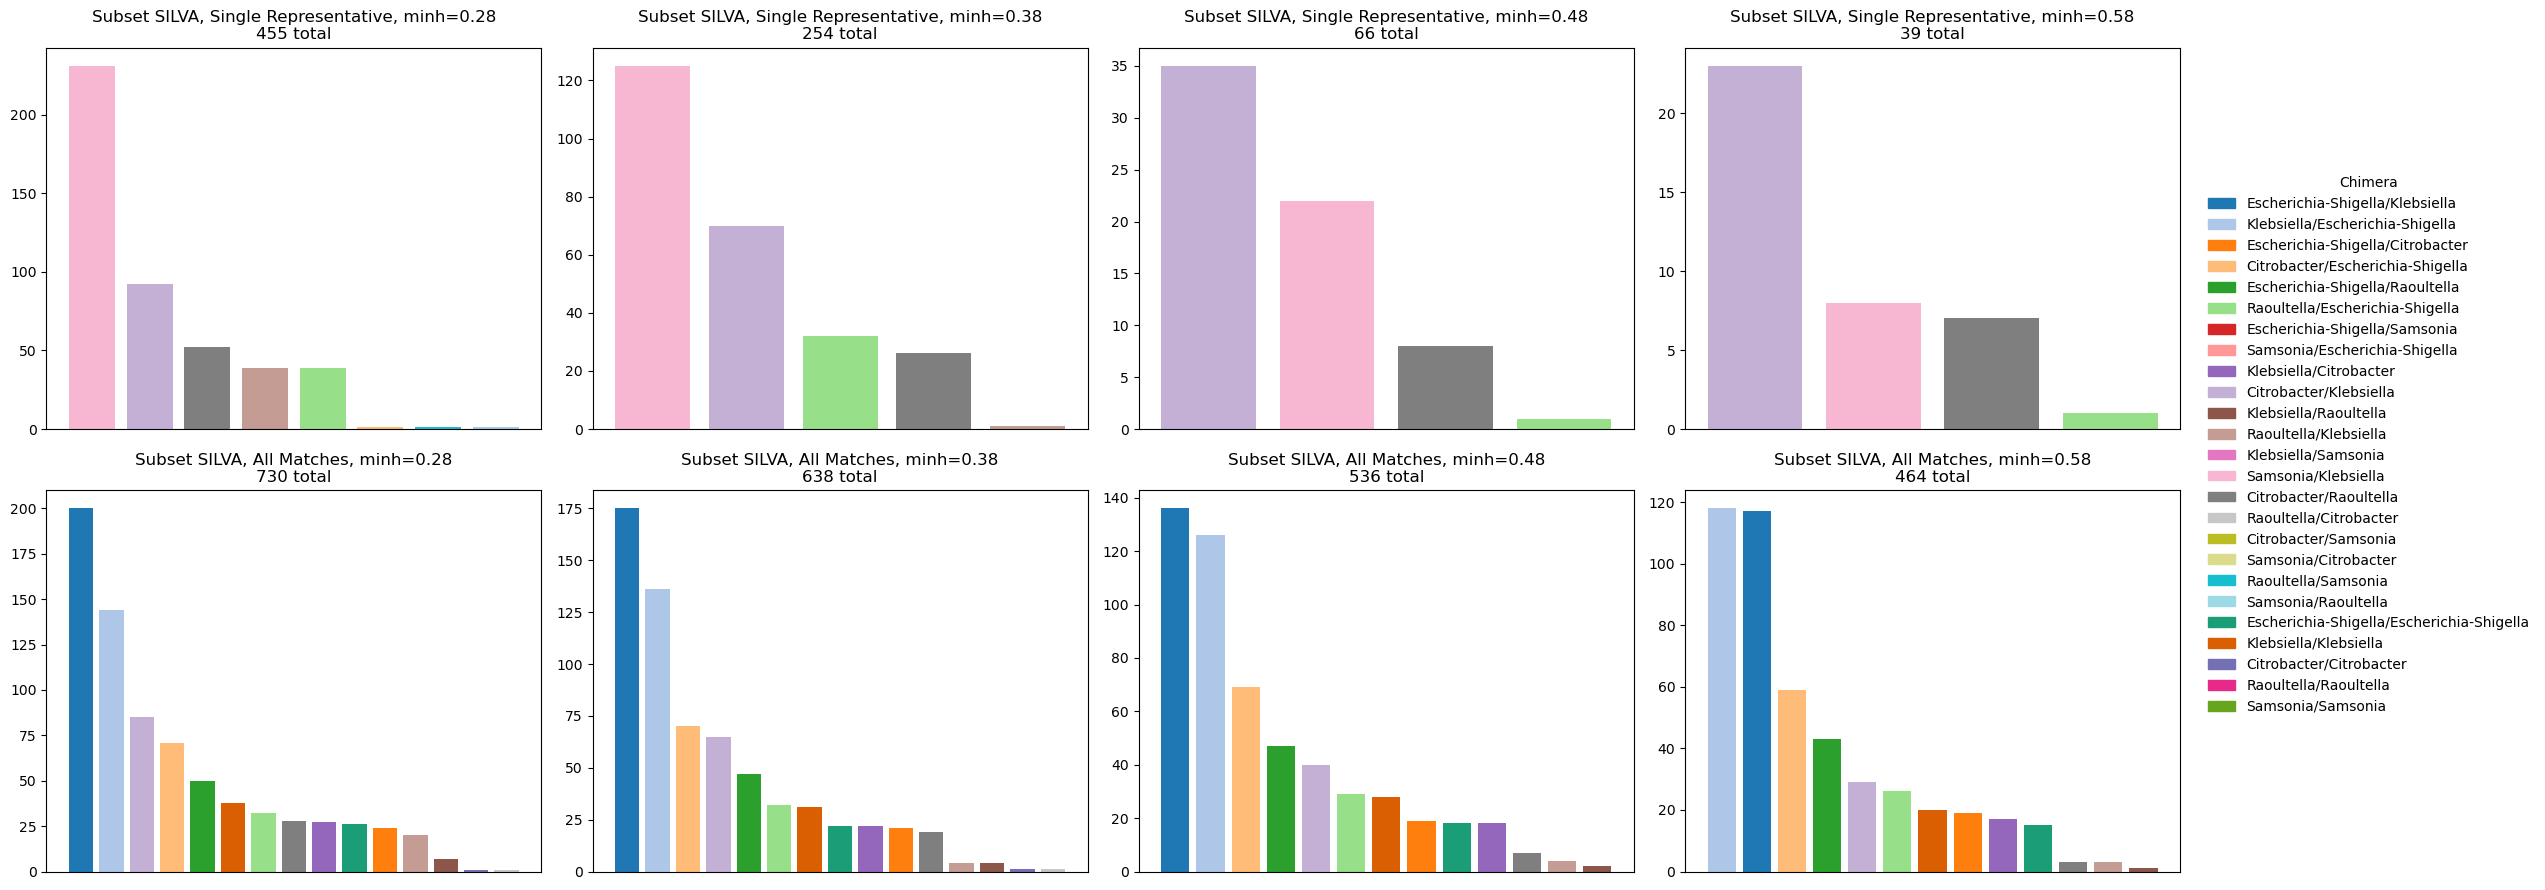

In [7]:
import matplotlib.pyplot as plt

genera = [
    "Escherichia-Shigella",
    "Klebsiella",
    "Citrobacter",
    "Raoultella",
    "Samsonia",
]

combinations = [f"{a}/{b}" for a in genera for b in genera]
combinations = [
    'Escherichia-Shigella/Klebsiella',
    'Klebsiella/Escherichia-Shigella',
    'Escherichia-Shigella/Citrobacter',
    'Citrobacter/Escherichia-Shigella',
    'Escherichia-Shigella/Raoultella',
    'Raoultella/Escherichia-Shigella',
    'Escherichia-Shigella/Samsonia',
    'Samsonia/Escherichia-Shigella',
    'Klebsiella/Citrobacter',
    'Citrobacter/Klebsiella',
    'Klebsiella/Raoultella',
    'Raoultella/Klebsiella',
    'Klebsiella/Samsonia',
    'Samsonia/Klebsiella',
    'Citrobacter/Raoultella',
    'Raoultella/Citrobacter',
    'Citrobacter/Samsonia',
    'Samsonia/Citrobacter',
    'Raoultella/Samsonia',
    'Samsonia/Raoultella',
    'Escherichia-Shigella/Escherichia-Shigella',
    'Klebsiella/Klebsiella',
    'Citrobacter/Citrobacter',
    'Raoultella/Raoultella',
    'Samsonia/Samsonia'
]

# Create concatenated colormap: tab20 + Dark2
tab20_colors = plt.cm.tab20(np.linspace(0, 1, 20))
dark2_colors = plt.cm.Dark2(np.linspace(0, 1, 8))
combined_colors = np.concatenate([tab20_colors, dark2_colors])

# Create manual combinations to color dictionary using concatenated colormap
combinations_colors = {combo: combined_colors[i % len(combined_colors)] for i, combo in enumerate(combinations)}

fig, axs = plt.subplots(2,4,figsize=(22,9))

for idx in range(len(alns)):
    outfile_i = outfiles[idx]
    if "subset" in outfile_i:
        df = tsvs[idx]
        keep_i = dataset[idx]
        minh_i = minh[idx]
        i = ds_mapper[keep_i]
        j = minh_mapper[minh_i]

        chimeras_i = df.loc[df["YN"] != "N"].copy()
        chimeras_i["A"] = chimeras_i["A"].str.split(";", expand=True).iloc[:, -2]
        chimeras_i["B"] = chimeras_i["B"].str.split(";", expand=True).iloc[:, -2]
        chimeras_i["Chimera"] = chimeras_i["A"] + "/" + chimeras_i["B"]
        ccts = chimeras_i["Chimera"].value_counts().reset_index()

        # Map colors to the data
        colors = [combinations_colors.get(combo, 'gray') for combo in ccts["Chimera"]]
        
        # Create barplot without hue to avoid automatic legend creation
        bars = axs[i,j].bar(range(len(ccts)), ccts["count"], color=colors)
        axs[i,j].set_title(f"Subset SILVA, {keep_i}, minh={minh_i}\n{alns[idx].shape[0]} total")
        axs[i,j].set_xticks([])

# Create single legend to the right of the overall plot
legend_handles = [plt.Rectangle((0,0),1,1, color=combinations_colors[combo]) for combo in combinations]
fig.legend(legend_handles, combinations, title="Chimera", bbox_to_anchor=(1, 0.5), loc='center left', frameon=False)

plt.tight_layout()
plt.show()

## Read Quality Check

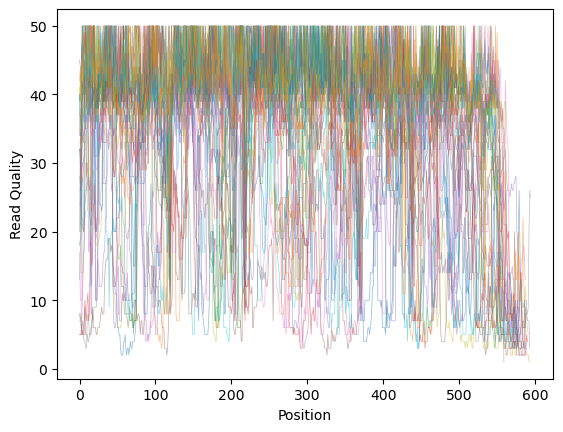

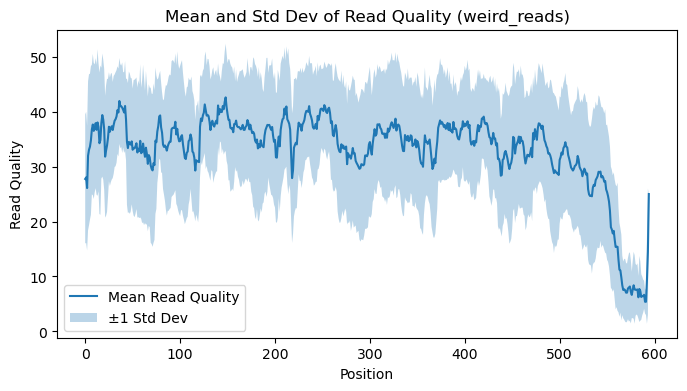

In [8]:
# Let's plot read quality for some of these

weird_reads = [
    "1985_DKDTH4_1",
    "876_DKDTH4_1",
    "2890_DKDTH4_1",
    "122_DKDTH4_1",
    "587_DKDTH4_1",
    "3046_DKDTH4_1",
    "1200_DKDTH4_1",
    "1648_DKDTH4_1",
    "3094_DKDTH4_1",
    "4805_DKDTH4_1",
    "818_DKDTH4_1",
    "4821_DKDTH4_1",
    "3203_DKDTH4_1",
    "1400_DKDTH4_1",
    "2749_DKDTH4_1",
    "718_DKDTH4_1",
    "2765_DKDTH4_1",
    "1847_DKDTH4_1",
    "431_DKDTH4_1",
    "3667_DKDTH4_1",
    "1233_DKDTH4_1",
    "3331_DKDTH4_1",
    "3032_DKDTH4_1",
    "1262_DKDTH4_1",
    "838_DKDTH4_1",
    "2110_DKDTH4_1",
    "1135_DKDTH4_1",
    "1729_DKDTH4_1",
    "149_DKDTH4_1",
    "3222_DKDTH4_1",
    "288_DKDTH4_1",
    "3806_DKDTH4_1",
]

readQs = []

reads = SeqIO.parse("/groups/cress/projects/efactors/jack/insertion_mapping/sequences/reads/DKDTH4_1_MCKanCm_gPCR.fastq", "fastq")
for read in reads:
    if read.id in weird_reads:
        readQs.append(read.letter_annotations["phred_quality"])

for i in readQs:
    plt.plot(np.arange(len(i)), i, linewidth=.5, alpha=0.5)
# plt.xlim(400,600)
plt.ylabel("Read Quality")
plt.xlabel("Position")
plt.show()
# Plot mean and stddev using seaborn
# import seaborn as sns

# Pad all read quality arrays to the same length with np.nan for proper mean/std calculation
maxlen = max(len(q) for q in readQs)
readQs_padded = []
for q in readQs:
    padded_q = np.full(maxlen, np.nan)
    padded_q[:len(q)] = q
    readQs_padded.append(padded_q)
readQs_padded = np.array(readQs_padded)

mean_q = np.nanmean(readQs_padded, axis=0)
std_q = np.nanstd(readQs_padded, axis=0)
positions = np.arange(maxlen)

plt.figure(figsize=(8,4))
sns.lineplot(x=positions, y=mean_q, label="Mean Read Quality")
plt.fill_between(positions, mean_q-std_q, mean_q+std_q, alpha=0.3, label="±1 Std Dev")
plt.ylabel("Read Quality")
plt.xlabel("Position")
plt.title("Mean and Std Dev of Read Quality (weird_reads)")
plt.legend()
plt.show()

In [9]:
reads = SeqIO.parse("/groups/cress/projects/efactors/jack/insertion_mapping/sequences/reads/DKDTH4_1_MCKanCm_gPCR.fastq", "fastq")
for read in reads:
    if read.id == weird_reads[0]:
        print(read.seq)
        print(read.seq.reverse_complement())


TTACCCTGTTATCCCTAGGATAATACAACCGCGGCTGCTGGCACGGAGTTAGCCGGTGCTTCTTCTGCGGGTAACGTCAATGAGCAAAGGTATTAACTTTACTCCCTTCCTCCCCGCTGAAAGTACTTTACAACCCGAAGGCCTTCTTCATACACGCGGCATGGCTGCATCAGGCTTGCGCCCATTGTGCAATATTCCCCACTGCTGCCTCCCGTAGGAGTCTGGACCGTGTCTCAGTTCCAGTGTGGCTGGTCATCCTCTCAGACCAGCTAGGGATCGTCGCCTAGGTGAGCCATTACCCCACCTACTAGCTAATCCCATCTGGGCACATCTGATGGCATGAGGCCCGAAGGTCCCCCACTTTGGAACTGAGACACGGTCCAGACTCCTACGGGAGGCAGCAGTGGGGAATATTGCACAATGGGCGCAAGCCTGATGCAGCCATGCCGCGTGTATGAAGAAGGCCTTGGGGTGAAAGTACTTTCAGCGGGGAGGAAGGGAGTAAAGTTAATACCTTTGCTCGTTGACGTTACCCGCAGAAGAAGCACCGGCTAACTCCGTGCCAGCAGCCGCAGCATCAGGATAACAGGGTAAA
TTTACCCTGTTATCCTGATGCTGCGGCTGCTGGCACGGAGTTAGCCGGTGCTTCTTCTGCGGGTAACGTCAACGAGCAAAGGTATTAACTTTACTCCCTTCCTCCCCGCTGAAAGTACTTTCACCCCAAGGCCTTCTTCATACACGCGGCATGGCTGCATCAGGCTTGCGCCCATTGTGCAATATTCCCCACTGCTGCCTCCCGTAGGAGTCTGGACCGTGTCTCAGTTCCAAAGTGGGGGACCTTCGGGCCTCATGCCATCAGATGTGCCCAGATGGGATTAGCTAGTAGGTGGGGTAATGGCTCACCTAGGCGACGATCCCTAGCTGGTCTGAGAGGATGACCAGCCACACTGGAACTGAGACACGGTCCAGACTCCTACGGGAGGCAGCAGTGGGGAATAT

# Takeaways
- The apparent "chimeras" we can detect in Genious are probably just low-quality reads
- Subsetting the databases to genera we expect reduces some wonky alignment issues
### Potential plan:
Subset the SILVA database to the first 600nt and run UCHIME against that database 
with the default $h_{min}$ value of 0.28
`cutadapt --length 600 --fasta /shared/db/silva/latest/fasta/SILVA_138_SSURef_NR99_tax_silva_trunc.replace-whitespace.fasta > SILVA_138_SSURef_NR99_tax_silva_trunc.replace-whitespace.first600.fasta`

I'll also try trimming the pared-down SILVA and the Gold database and see how many of the chimeras match

```
vsearch \
    --uchime_ref LE_containing_amplicons.fasta \
    --db /groups/cress/projects/efactors/jack/insertion_mapping/sequences/SILVA_138_SSURef_NR99_tax_silva_trunc.replace-whitespace.first600.fasta \
    --threads 0 \
    --nonchimeras qc/nonchimeras.trimdb.fasta \
    --chimeras qc/chimeras.trimdb.fasta \
    --borderline qc/borderline.trimdb.fasta \
    --uchimeout qc/uchimeout.trimdb.txt \
    --uchimealns qc/uchimeout.trimdb.aln

Reading file /groups/cress/projects/efactors/jack/insertion_mapping/sequences/SILVA_138_SSURef_NR99_tax_silva_trunc.replace-whitespace.first600.fasta 100%  
306590400 nt in 510984 seqs, min 600, max 600, avg 600
Masking 100% 
Counting k-mers 100% 
Creating k-mer index 100% 
Detecting chimeras 100%  
Found 650 (28.7%) chimeras, 1582 (69.9%) non-chimeras,
and 32 (1.4%) borderline sequences in 2264 unique sequences.
Taking abundance information into account, this corresponds to
650 (28.7%) chimeras, 1582 (69.9%) non-chimeras,
and 32 (1.4%) borderline sequences in 2264 total sequences.
```

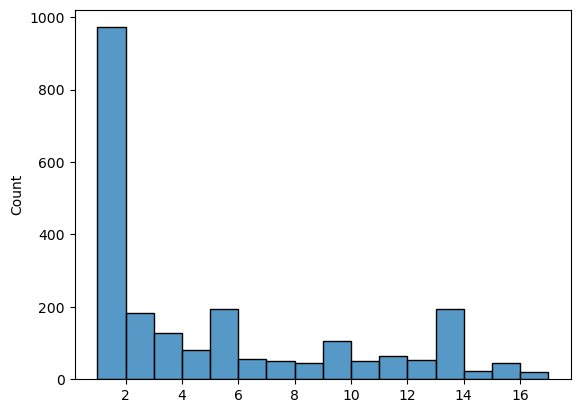

In [10]:
# Pretty obvious followup: are we finding the same chimeras w different parameters?
trunc_silva_chimeras = read_uchimeout("qc/uchimeout.trimdb.txt")["Q"]
chimeras = [trunc_silva_chimeras]

for idx in range(len(alns)):
    outfile_i = outfiles[idx]
    df = tsvs[idx]
    keep_i = dataset[idx]
    minh_i = minh[idx]
    i = ds_mapper[keep_i]
    j = minh_mapper[minh_i]

    chimeras_i = df.loc[df["YN"] != "N"].copy()
    chimeras.append(chimeras_i["Q"])

unique_chimeras = pd.concat(chimeras).unique()
ccts = []

for i in unique_chimeras:
    cct = 0
    for j in chimeras:
        if i in j.values:
            cct += 1
    ccts.append(cct)

sns.histplot(ccts)
plt.show()


In [11]:
len(ccts) == len(unique_chimeras)
print(len(chimeras))
pd.Series(ccts).value_counts()
# pd.Series(ccts).value_counts(normalize=True)

17


1     972
13    195
5     194
2     182
3     129
9     106
4      80
11     65
6      56
12     53
7      50
10     50
8      45
15     44
14     23
17     15
16      5
Name: count, dtype: int64